# Lab 2 : OD Matrices analytics

## Setup of datasets and visualization

In [13]:
%pip install geopandas "folium>=0.12" matplotlib mapclassify 

Note: you may need to restart the kernel to use updated packages.


In [14]:
%pip install geopandas
%pip install pymongo

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [15]:
import pymongo as pm
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timezone
import geopandas as gpd
from shapely.geometry import box
from geopandas import GeoDataFrame
from shapely.geometry import box
from branca.colormap import linear
from IPython.display import display
import seaborn as sns
import ipywidgets as widgets
from itertools import combinations
import json, os
from matplotlib.path import Path

os.makedirs('out', exist_ok=True)

In [16]:
client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [17]:
db= client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [18]:
pipe = [
    {
        "$project": {
            "hour": {"$hour": "$init_date"},  
            "day": {"$dayOfWeek": "$init_date"},
            "init_location": 1,
            "final_location": 1,
        }
    },
    {
        "$match": {
            "day": {"$gte":1,"$lte":6},
            "hour": {"$gte":0,"$lte":12},
             "driving.distance": {"$gt": 0}
        }
    },
    {
        "$count": "tot"
    }
]

pb_coll.aggregate(pipe)

In [19]:
Q= 0.90

def load_wtime(db, coll, carsharing=True):
    if carsharing:
        pipe = [
            {
                "$match": {
                    "driving.duration": {"$gt": 0},
                    "driving.distance": {"$gt": 0}
                }
            },
            {
                "$project": {
                    "_id": 0,
                    "init_time": 1,
                    "final_time": 1,
                    "duration": "$driving.duration",
                    "day": {
                        "$dateToString": {
                            "date": "$init_date",
                            "format": "%Y-%m-%d"
                        }
                    },
                    "week": {"$isoWeek": "$init_date"},
                    "iso_year": {"$isoWeekYear": "$init_date"},
                    "dow": {"$isoDayOfWeek": "$init_date"},
                    "hour": {"$hour": "$init_date"},
                    "vendor": 1,
                    "init_address": 1,
                    "final_address": 1,
                    "plate": 1,
                    "init_loc": 1,
                    "final_loc": 1,
                    "driving": 1,
                    "walking": 1,
                    'init_date':1
                }
            }
        ]

    else:
        raise NotImplementedError(
            "Non-carsharing data processing is not implemented yet."
        )

    collection = db[coll] if isinstance(coll, str) else coll
    df = pd.DataFrame(collection.aggregate(pipe, allowDiskUse=True))

    if df.empty:
        print("Warning: MongoDB query returned no documents.")
        return df

    df["duration_min"] = df["duration"] / 60

    df["driving_distance_km"] = df["driving"].apply(
        lambda x: x["distance"] / 1000
        if isinstance(x, dict) else np.nan
    )

    df["walking_duration_min"] = df["walking"].apply(
        lambda x: x["duration"] / 60
        if isinstance(x, dict) else np.nan
    )

    return df



def best_zone(x, q=Q, log=True, threshold=False, min_duration=1.0):
    x = np.sort(np.asarray(x, dtype=float))
    if threshold:
        x = x[x >= min_duration]
    else:
        x = x[x >= 0]
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    k = int(np.ceil(q * n))
    t = np.log(x) if log else x
    widths = t[k - 1:] - t[:n - k + 1]
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=Q, col="duration_min", log=True, threshold=False):
    a, b = best_zone(df[col].values, q, log, threshold)
    return df[df[col].between(a, b)].copy(), (a, b)


def get_filtered_data(db,coll,q=Q,carsharing=True,verbose=True,return_extra=False):
    raw = load_wtime(db=db,coll=coll,carsharing=carsharing)

    if raw.empty:
        raise ValueError("No data returned by MongoDB.")

    filtered, zone = keep_best_zone(raw, q=q)

    if verbose:
        a, b = zone
        n0, n1 = len(raw), len(filtered)
        percentage = n1 / n0 if n0 else 0

        print(
            f"zone = [{a:.1f}, {b:.1f}] min "
            f"-> {n1}/{n0} gardés ({percentage:.1%})"
        )

    if return_extra:
        return filtered, {"raw": raw, "zone": zone}

    return filtered

# Q1

For this question we started to look at the data to see if we needed to adapt our filtering from the first lab.

In [20]:
def load_raw(coll, city="Torino"):
    pipe = [
        {
            "$match": {
                "city": city,
               }
        },
        {"$project": {
            "_id": 0,
            "plate": 1,
            "init_date": 1, "final_date": 1,
            "init_time": 1, "final_time": 1,
            "init_loc": 1, "final_loc": 1,
            "drv_dur": "$driving.duration",
            "drv_dist": "$driving.distance",
        }},
    ]
    df = pd.DataFrame(coll.aggregate(pipe, allowDiskUse=True))
    df["rental_min"] = (df["final_time"] - df["init_time"]) / 60
    df["drv_dist_km"] = df["drv_dist"] / 1000
    df["init_date"] = pd.to_datetime(df["init_date"])
    # coordinates to test "start == end"
    df["same_loc"] = df["init_loc"].apply(lambda x: tuple(x["coordinates"])) == \
                     df["final_loc"].apply(lambda x: tuple(x["coordinates"]))
    return df.drop(columns=["init_loc", "final_loc"])

raw = {
    "Car2Go": load_raw(pb_coll),
    "Enjoy":  load_raw(pb_coll_enjoy),
}

def explore(df, name):
    print(f"--- {name} ---")
    print("duration < 1 min      :", (df.rental_min < 1).sum())
    print("duration > 3 h        :", (df.rental_min > 180).sum())
    print("duration > 24 h       :", (df.rental_min > 1440).sum())
    print("distance <= 0         :", (df.drv_dist <= 0).sum())
    print("start == end          :", df.same_loc.sum())
    print(df[["rental_min", "drv_dist_km"]].describe(percentiles=[.01, .05, .5, .95, .99]))

for name, df in raw.items():
    explore(df, name)

--- Car2Go ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 82477
start == end          : 0
          rental_min    drv_dist_km
count  121667.000000  121667.000000
mean       20.889914       1.251278
std         9.849642       2.200316
min         2.100000      -0.001000
1%          4.750000      -0.001000
5%          7.633333      -0.001000
50%        19.433333      -0.001000
95%        39.650000       5.789000
99%        51.750000       8.347680
max        59.983333      33.401000
--- Enjoy ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 61447
start == end          : 0
         rental_min   drv_dist_km
count  97173.000000  97173.000000
mean      23.405766      1.494120
std       10.423864      2.434082
min        3.066667     -0.001000
1%         7.616667     -0.001000
5%         8.466667     -0.001000
50%       20.533333     -0.001000
95%       44.316667      6.278000
9

We can see that there is a lot of duration below 0 so we just filter it in the pipe.\
The only filter needed is a distance one. It cut 67.79% data for the car2go database and 63.23% for the enjoy Database.

In [21]:
#we add the columns for the coordinates
bookings = {'car2go': load_wtime(db, pb_coll), 'enjoy': load_wtime(db, pb_coll_enjoy)}
for name, df in bookings.items():
    
    df['orig_lon'] = df['init_loc'].apply(lambda p: p['coordinates'][0])
    df['orig_lat'] = df['init_loc'].apply(lambda p: p['coordinates'][1])
    df['dest_lon'] = df['final_loc'].apply(lambda p: p['coordinates'][0])
    df['dest_lat'] = df['final_loc'].apply(lambda p: p['coordinates'][1])
    
    print(f'{name}: {len(df)} rentals kept')

car2go: 39190 rentals kept
enjoy: 35726 rentals kept


In [22]:
# order of the features in TorinoZonescol.geojson (checked against the IMQ zone list)
FILE_ORDER = [f'Q{i:03d}' for i in range(1, 20)] + ['Q021', 'Q022', 'Q020', 'Q023']

def load_zones(path, names_path='data/IMQ/IMQData/tab_zone_IMQ.csv'):
    """23 zones of Torino: {code: geometry}, sorted list of codes, {code: name}."""
    with open(path) as f:
        fc = json.load(f)
    zones = {code: feature['geometry'] for code, feature in zip(FILE_ORDER, fc['features'])}
    table = pd.read_csv(names_path, encoding='latin-1', dtype=str).set_index('COD_ZONA')['nome_zona']
    names = {code: table[code].replace('TORINO - ', '').title() for code in zones}
    return zones, sorted(zones), names


def point_zone(lon, lat, zones):
    """Zone code of each point (lon, lat); None if outside all zones."""
    pts = np.column_stack([np.asarray(lon, float), np.asarray(lat, float)])
    out = np.full(len(pts), None, dtype=object)
    for code in sorted(zones):
        geom = zones[code]
        polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        inside = np.zeros(len(pts), dtype=bool)
        for poly in polys:
            m = Path(poly[0]).contains_points(pts)
            for hole in poly[1:]:
                m &= ~Path(hole).contains_points(pts)
            inside |= m
        out[inside & pd.isna(out)] = code
    return out


def assign_zones(df, zones):
    """Adds orig/dest zone codes and keeps only trips starting and ending inside the zones."""
    df = df.copy()
    df['orig'] = point_zone(df.orig_lon, df.orig_lat, zones)
    df['dest'] = point_zone(df.dest_lon, df.dest_lat, zones)
    inside = df.dropna(subset=['orig', 'dest'])
    print(f'{len(inside)}/{len(df)} trips inside the Torino zones ({len(inside) / len(df):.1%})')
    return inside

In [23]:
def add_time_columns(df):
    """Date, hour, day of week (0 = Monday) and calendar (ISO) week of each trip."""
    df = df.copy()
    d = pd.to_datetime(df['init_date'])
    df['date'] = d.dt.strftime('%Y-%m-%d')
    df['hour'] = d.dt.hour
    df['dow'] = d.dt.dayofweek
    df['week'] = d.dt.isocalendar().week.astype(int)
    return df


def select_period(df, days='all', hours=None, weeks=None):
    """days: 'all', 'weekdays' or 'weekend'; hours: (start, end), e.g. (22, 6) goes over midnight;
    weeks: list of calendar weeks."""
    mask = pd.Series(True, index=df.index)
    if days == 'weekdays':
        mask &= df.dow < 5
    elif days == 'weekend':
        mask &= df.dow >= 5
    if hours is not None:
        start, end = hours
        if start <= end:
            mask &= (df.hour >= start) & (df.hour < end)
        else:
            mask &= (df.hour >= start) | (df.hour < end)
    if weeks is not None:
        mask &= df.week.isin(weeks)
    return df[mask]

In [24]:
def od_matrix(df, zones_list, norm=True):
    """23 x 23 OD matrix (pivot table of trip counts); pairs without trips = 0; normalized to sum 1."""
    m = pd.pivot_table(df, index='orig', columns='dest', values='duration_min',
                       aggfunc='count', fill_value=0)
    m = m.reindex(index=zones_list, columns=zones_list, fill_value=0)
    m.index.name, m.columns.name = 'orig', 'dest'
    return m / m.values.sum() if norm else m


def tvd(A, B):
    """Total variation distance in %: 0 = identical, 100 = completely different."""
    return 0.5 * np.abs(A.values - B.values).sum() * 100


def top_changes(A, B, label_a='A', label_b='B', n=10):
    """The n OD pairs whose share of trips changes the most between A and B (percentage points)."""
    D = (A - B).stack()
    idx = D.abs().sort_values(ascending=False).index[:n]
    return pd.DataFrame({
        'origin': [f'{o} {ZONE_NAMES[o]}' for o, _ in idx],
        'destination': [f'{d} {ZONE_NAMES[d]}' for _, d in idx],
        f'{label_a} (%)': [A.loc[o, d] * 100 for o, d in idx],
        f'{label_b} (%)': [B.loc[o, d] * 100 for o, d in idx],
        'difference (p.p.)': [D[(o, d)] * 100 for o, d in idx],
    }).round(2)

In [25]:
from matplotlib.colors import LogNorm

def zone_labels(codes):
    return [f'{c} {ZONE_NAMES.get(c, "")}' for c in codes]


def plot_heatmaps(mats, title='', fname=None):
    """mats = {label: OD matrix}, side by side, same log colour scale; cells with no trips in grey."""
    vals = np.concatenate([m.values.ravel() for m in mats.values()])
    pos = vals[vals > 0]
    norm = LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max())
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#dddddd')
    fig, axes = plt.subplots(1, len(mats), figsize=(7.5 * len(mats), 7), squeeze=False, constrained_layout=True)
    for ax, (name, m) in zip(axes[0], mats.items()):
        im = ax.imshow(np.ma.masked_where(m.values <= 0, m.values), cmap=cmap, norm=norm)
        ax.set_title(name, fontsize=12)
        ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(zone_labels(m.columns), rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index))); ax.set_yticklabels(zone_labels(m.index), fontsize=7)
        ax.set_xlabel('destination zone'); ax.set_ylabel('origin zone')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.7, label='fraction of trips (log scale)')
    fig.suptitle(title, fontsize=14)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()


def plot_difference(A, B, title='', fname=None):
    """Heatmap of A - B: red = more trips in A, blue = more in B."""
    D = A - B
    lim = np.abs(D.values).max()
    plt.figure(figsize=(8, 7))
    plt.imshow(D.values, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(label='A − B')
    plt.xticks(range(len(D.columns)), zone_labels(D.columns), rotation=90, fontsize=7)
    plt.yticks(range(len(D.index)), zone_labels(D.index), fontsize=7)
    plt.xlabel('destination zone'); plt.ylabel('origin zone'); plt.title(title)
    if fname: plt.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

### OD matrices on the 23 zones (all trips)

38941/39190 trips inside the Torino zones (99.4%)
35541/35726 trips inside the Torino zones (99.5%)


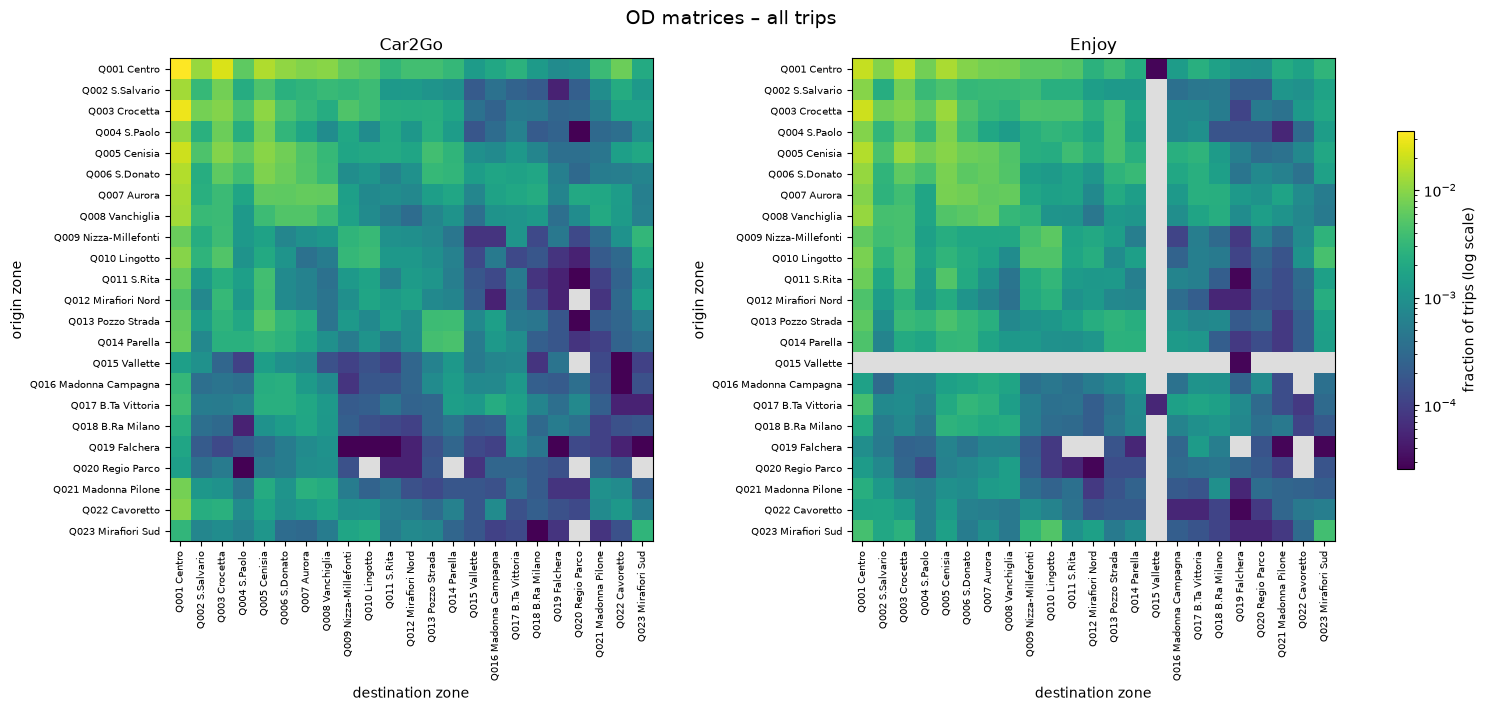

In [26]:
zones, ZONES, ZONE_NAMES = load_zones('data/IMQ/Zone/TorinoZonescol.geojson')
trips = {name: add_time_columns(assign_zones(df, zones)) for name, df in bookings.items()}

od_all = {name: od_matrix(df, ZONES) for name, df in trips.items()}
plot_heatmaps({'Car2Go': od_all['car2go'], 'Enjoy': od_all['enjoy']}, 'OD matrices – all trips', 'task1_od')

## Q1a – Different periods
Weekdays vs weekends, daytime (6–22h) vs night-time, for each platform.

In [27]:
DAY_HOURS = (6, 22)
PERIODS = {
    'Weekdays':   dict(days='weekdays'),
    'Weekends':   dict(days='weekend'),
    'Daytime':    dict(hours=DAY_HOURS),
    'Night-time': dict(hours=DAY_HOURS[::-1]),
}

od_periods = {}
for vendor, df in trips.items():
    od_periods[vendor] = {}
    for name, kw in PERIODS.items():
        sel = select_period(df, **kw)
        od_periods[vendor][name] = od_matrix(sel, ZONES)
        print(f'{vendor:7s} {name:11s}: {len(sel):6d} trips')

car2go  Weekdays   :  29027 trips
car2go  Weekends   :   9914 trips
car2go  Daytime    :  28240 trips
car2go  Night-time :  10701 trips
enjoy   Weekdays   :  26549 trips
enjoy   Weekends   :   8992 trips
enjoy   Daytime    :  23929 trips
enjoy   Night-time :  11612 trips


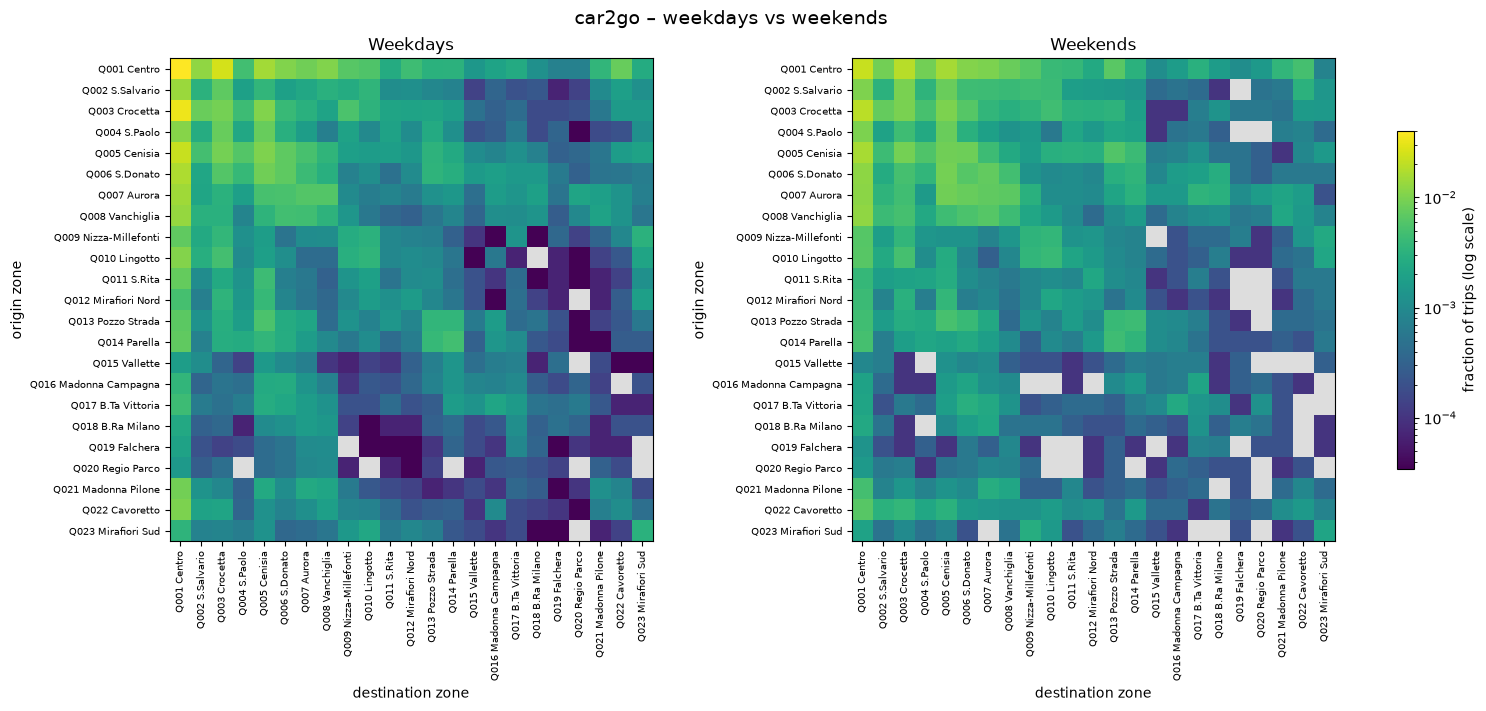

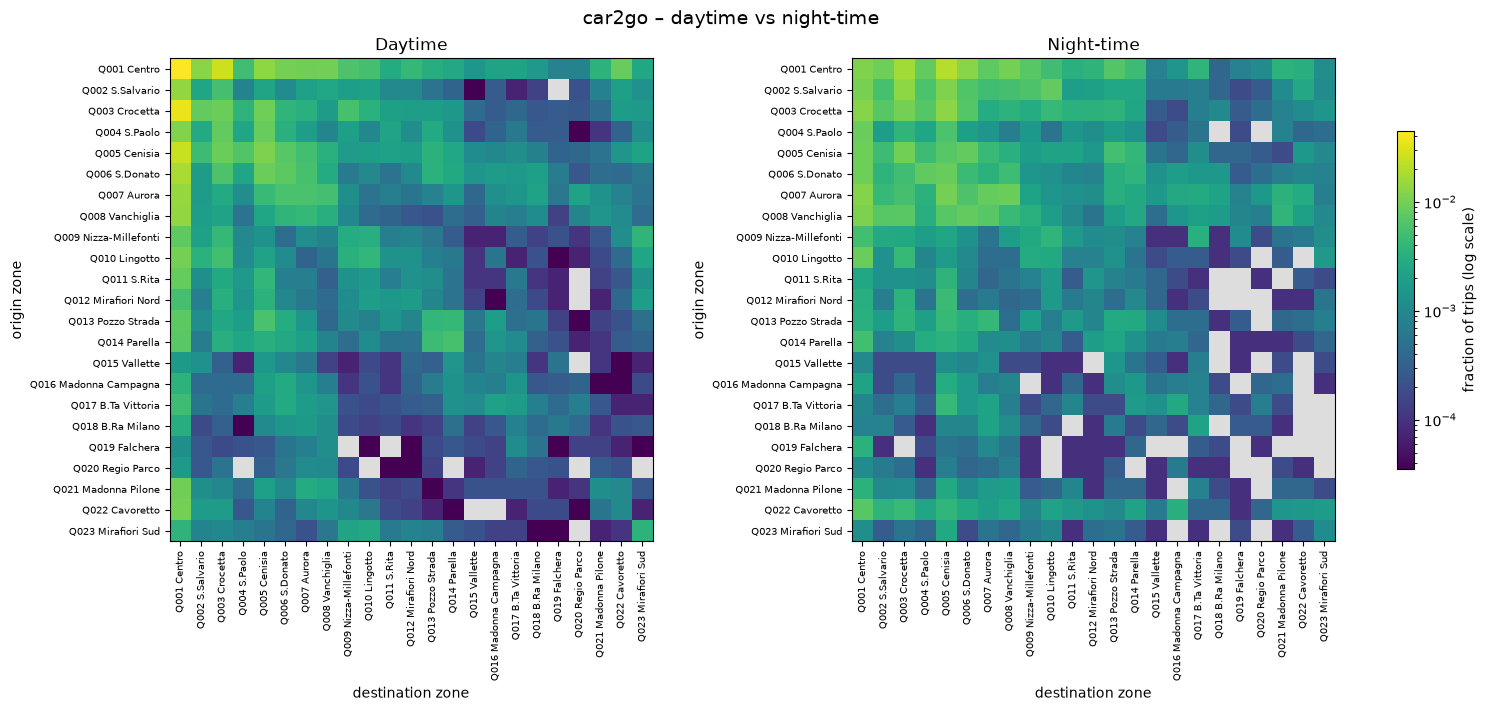

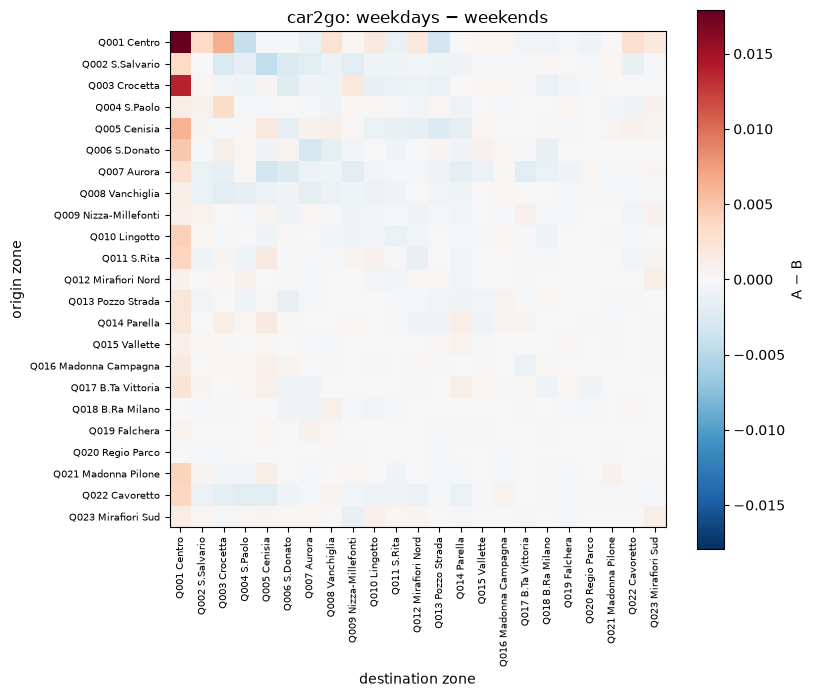

In [ ]:
# heatmaps of each period and differences (red = more in the first period, blue = more in the second)
for vendor, P in od_periods.items():
    plot_heatmaps({'Weekdays': P['Weekdays'], 'Weekends': P['Weekends']},
                  f'{vendor} – weekdays vs weekends', f'task1a_{vendor}_week')
    plot_heatmaps({'Daytime': P['Daytime'], 'Night-time': P['Night-time']},
                  f'{vendor} – daytime vs night-time', f'task1a_{vendor}_day')
    plot_difference(P['Weekdays'], P['Weekends'], f'{vendor}: weekdays − weekends', f'task1a_{vendor}_diff_week')
    plot_difference(P['Daytime'], P['Night-time'], f'{vendor}: daytime − night-time', f'task1a_{vendor}_diff_day')

In [ ]:
# how different (TVD) and where (OD pairs that change the most)
for vendor, P in od_periods.items():
    print(f"{vendor}: TVD weekdays vs weekends = {tvd(P['Weekdays'], P['Weekends']):.1f}%, "
          f"daytime vs night-time = {tvd(P['Daytime'], P['Night-time']):.1f}%")
    display(top_changes(P['Weekdays'], P['Weekends'], 'Weekdays', 'Weekends', n=5))
    display(top_changes(P['Daytime'], P['Night-time'], 'Daytime', 'Night-time', n=5))

## Q1b – Same period, different dates
Weekday OD matrices of different calendar weeks. Since the share of rentals without a route changes from day
to day, a week is used only if every weekday has at least 50% of the typical daily number of trips.

In [ ]:
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    print(vendor, '- weekday trips per calendar week (rows) and day (0 = Monday)')
    display(pd.crosstab(wd.week, wd.dow))

In [ ]:
def full_weeks(df, min_share=0.5):
    """Weeks where every weekday has at least min_share of the typical (median) daily number of trips."""
    wd = select_period(df, days='weekdays')
    per_day = pd.crosstab(wd.week, wd.dow)
    typical = np.median(per_day.values[per_day.values > 0])
    return list(per_day.index[(per_day >= min_share * typical).all(axis=1)])

FULL_WEEKS = {vendor: full_weeks(df) for vendor, df in trips.items()}
print(FULL_WEEKS)
WEEK_A, WEEK_B = 41, 43     # must be in both lists above

In [ ]:
od_weeks = {}
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    od_weeks[vendor] = {w: od_matrix(wd[wd.week == w], ZONES) for w in FULL_WEEKS[vendor]}
    A, B = od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]
    plot_heatmaps({f'Weekdays – week {WEEK_A}': A, f'Weekdays – week {WEEK_B}': B},
                  f'{vendor} – same period, two different weeks', f'task1b_{vendor}_weeks')
    plot_difference(A, B, f'{vendor}: week {WEEK_A} − week {WEEK_B}', f'task1b_{vendor}_diff')

# TVD between all pairs of complete weeks
rows = [{'vendor': vendor, 'pair': f'{w1} vs {w2}', 'TVD (%)': tvd(mats[w1], mats[w2])}
        for vendor, mats in od_weeks.items() for w1, w2 in combinations(mats, 2)]
week_tvd = pd.DataFrame(rows).round(1)
week_tvd.groupby('vendor')['TVD (%)'].describe()

In [ ]:
# reference for random noise: the same week split into two random halves
week = select_period(trips['car2go'], days='weekdays', weeks=[WEEK_A])
half1 = week.sample(frac=0.5, random_state=0)
half2 = week.drop(half1.index)
print(f'Car2Go week {WEEK_A}, two random halves: TVD = {tvd(od_matrix(half1, ZONES), od_matrix(half2, ZONES)):.1f}%')

In [ ]:
# summary: different dates vs different periods
comparison = {}
for vendor, df in trips.items():
    week_a = select_period(df, weeks=[WEEK_A])
    P = od_periods[vendor]
    comparison[vendor] = {
        f'Weekdays: week {WEEK_A} vs {WEEK_B}':          tvd(od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]),
        'Weekdays: all pairs of complete weeks (mean)': week_tvd[week_tvd.vendor == vendor]['TVD (%)'].mean(),
        f'Weekdays vs weekend, same week {WEEK_A}':       tvd(od_matrix(select_period(week_a, days='weekdays'), ZONES),
                                                           od_matrix(select_period(week_a, days='weekend'), ZONES)),
        'Weekdays vs weekends, all data':               tvd(P['Weekdays'], P['Weekends']),
        'Daytime vs night-time, all data':              tvd(P['Daytime'], P['Night-time']),
    }
comparison = pd.DataFrame(comparison).round(1)
comparison

## Q1c – Same period and dates, Car2Go vs Enjoy
Weekdays of week WEEK_A for both platforms, then all dates in common.

In [ ]:
common_dates = sorted(set(trips['car2go'].date) & set(trips['enjoy'].date))
same = {v: df[df.date.isin(common_dates)] for v, df in trips.items()}
print(f'{len(common_dates)} common dates: {common_dates[0]} -> {common_dates[-1]}')

od_vendor = {v: od_matrix(select_period(df, days='weekdays', weeks=[WEEK_A]), ZONES) for v, df in same.items()}
plot_heatmaps({f'Car2Go – weekdays week {WEEK_A}': od_vendor['car2go'],
               f'Enjoy – weekdays week {WEEK_A}': od_vendor['enjoy']},
              'Same period and dates, different platforms', 'task1c_heatmaps')
plot_difference(od_vendor['car2go'], od_vendor['enjoy'], f'Car2Go − Enjoy (weekdays, week {WEEK_A})', 'task1c_diff')

print(f"TVD Car2Go vs Enjoy, weekdays week {WEEK_A}: {tvd(od_vendor['car2go'], od_vendor['enjoy']):.1f}%")
print(f"TVD Car2Go vs Enjoy, all common dates: {tvd(od_matrix(same['car2go'], ZONES), od_matrix(same['enjoy'], ZONES)):.1f}%")

In [ ]:
# share of trips starting (pO) and ending (pD) in each zone, and OD pairs that differ the most
od_same = {v: od_matrix(df, ZONES) for v, df in same.items()}
coverage = pd.DataFrame({
    'zone': zone_labels(ZONES),
    'Car2Go pO (%)': od_same['car2go'].sum(axis=1).values * 100,
    'Enjoy pO (%)':  od_same['enjoy'].sum(axis=1).values * 100,
    'Car2Go pD (%)': od_same['car2go'].sum(axis=0).values * 100,
    'Enjoy pD (%)':  od_same['enjoy'].sum(axis=0).values * 100,
})
coverage['diff pO (p.p.)'] = coverage['Car2Go pO (%)'] - coverage['Enjoy pO (%)']
display(coverage.round(2).sort_values('diff pO (p.p.)', ascending=False))
top_changes(od_vendor['car2go'], od_vendor['enjoy'], 'Car2Go', 'Enjoy')